# 03 — Exploratory data analysis

This notebook explores how temperature, heat extremes and precipitation evolved across six Italian cities from 1940 through 2025. It addresses the descriptive part of the project questions before formal statistical inference.

The analysis includes:

- temperature distributions and monthly seasonality;
- annual temperature evolution and 10-year rolling means;
- annual and monthly anomalies relative to 1961–1990;
- exploratory warming rates;
- hot days, tropical nights and city-specific heatwaves;
- annual precipitation, heavy-rain days and long-term patterns;
- comparison between 1941–1970 and 1996–2025.

All figures are saved in `reports/figures/eda`, and derived analysis tables are saved in `data/processed`.

## 1. Project setup

In [23]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "scripts").is_dir():
    raise RuntimeError(
        "Could not locate the project root. Start Jupyter from the "
        "Weather-Report repository or its notebooks directory."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT.name}")

Project root: Weather-Report


In [24]:
import matplotlib.pyplot as plt
import pandas as pd

from scripts import (
    add_annual_temperature_anomalies,
    add_calendar_features,
    add_significance_labels,
    calculate_annual_indicators,
    calculate_heatwave_indicators,
    calculate_monthly_climatology,
    calculate_monthly_summary,
    calculate_monthly_temperature_anomalies,
    calculate_seasonal_indicators,
    compare_climate_periods,
    configure_plot_style,
    estimate_temperature_trends,
    fit_city_year_interaction,
    fit_grouped_linear_trends,
    merge_annual_indicators,
    plot_annual_temperature,
    plot_annual_temperature_anomalies,
    plot_extreme_heat_indicators,
    plot_monthly_anomaly_heatmaps,
    plot_monthly_climatology,
    plot_precipitation_indicators,
    plot_temperature_distributions,
    plot_temperature_trends,
    plot_trend_heatmap,
    plot_trend_intervals,
    save_figure,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
configure_plot_style()

## 2. Load the validated daily dataset

The EDA uses only the processed dataset produced by notebook 02. The checks below prevent accidental analysis of a partial or structurally different file.

In [25]:
DATA_FILE = PROJECT_ROOT / "data" / "processed" / "weather_daily_1940_2025.csv"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "eda"
DERIVED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
BASELINE_START = 1961
BASELINE_END = 1990

if not DATA_FILE.is_file():
    raise FileNotFoundError(
        "Processed data not found. Run 02_data_cleaning.ipynb first."
    )

weather = pd.read_csv(DATA_FILE, parse_dates=["date"])
required_columns = {
    "city", "city_slug", "date", "temperature_2m_mean",
    "temperature_2m_max", "temperature_2m_min", "precipitation_sum",
}
missing_columns = required_columns - set(weather.columns)
if missing_columns:
    raise ValueError(f"Processed dataset is missing columns: {sorted(missing_columns)}")

display_data_path = Path(PROJECT_ROOT.name) / DATA_FILE.relative_to(PROJECT_ROOT)
print(f"Loaded: {display_data_path}")
print(f"Shape: {weather.shape[0]:,} rows × {weather.shape[1]} columns")

Loaded: Weather-Report/data/processed/weather_daily_1940_2025.csv
Shape: 188,472 rows × 13 columns


In [26]:
coverage = (
    weather.groupby(["city", "city_slug"], observed=True)
    .agg(
        first_date=("date", "min"),
        last_date=("date", "max"),
        observations=("date", "size"),
        missing_temperature=("temperature_2m_mean", lambda values: values.isna().sum()),
        missing_precipitation=("precipitation_sum", lambda values: values.isna().sum()),
    )
    .reset_index()
)
display(coverage)

,city,city_slug,first_date,last_date,observations,missing_temperature,missing_precipitation
0,Bari,bari,1940-01-01,2025-12-31,31412,0,1
1,Cagliari,cagliari,1940-01-01,2025-12-31,31412,0,1
2,Milan,milan,1940-01-01,2025-12-31,31412,0,1
3,Palermo,palermo,1940-01-01,2025-12-31,31412,0,1
4,Rome,rome,1940-01-01,2025-12-31,31412,0,1
5,Turin,turin,1940-01-01,2025-12-31,31412,0,1


Each city should contain 31,412 daily observations. The single missing precipitation value per city is the documented 1 January 1940 archive-boundary exception; temperature coverage is complete.

## 3. Calendar features and descriptive statistics

The daily dataset is enriched with year, month, meteorological season and decade. December is assigned to the following season year so winters can later be analysed without splitting December from January and February.

In [27]:
weather_features = add_calendar_features(weather)

descriptive_statistics = (
    weather_features.groupby(["city", "city_slug"], observed=True)
    .agg(
        mean_temperature=("temperature_2m_mean", "mean"),
        temperature_std=("temperature_2m_mean", "std"),
        coldest_daily_minimum=("temperature_2m_min", "min"),
        hottest_daily_maximum=("temperature_2m_max", "max"),
        mean_daily_precipitation=("precipitation_sum", "mean"),
        wettest_day=("precipitation_sum", "max"),
    )
    .round(2)
    .reset_index()
)
display(descriptive_statistics)

,city,city_slug,mean_temperature,temperature_std,coldest_daily_minimum,hottest_daily_maximum,mean_daily_precipitation,wettest_day
0,Bari,bari,17.35,6.74,-5.3,44.5,1.69,93.7
1,Cagliari,cagliari,17.50,5.89,-0.1,40.9,1.21,67.6
2,Milan,milan,13.09,8.07,-18.0,39.4,3.14,96.9
3,Palermo,palermo,18.54,6.32,-1.9,43.7,1.68,78.7
4,Rome,rome,15.76,6.93,-13.7,40.4,2.36,105.2
5,Turin,turin,12.82,8.06,-19.8,39.5,2.59,125.2


Weather-Report/reports/figures/eda/01_temperature_distributions.png


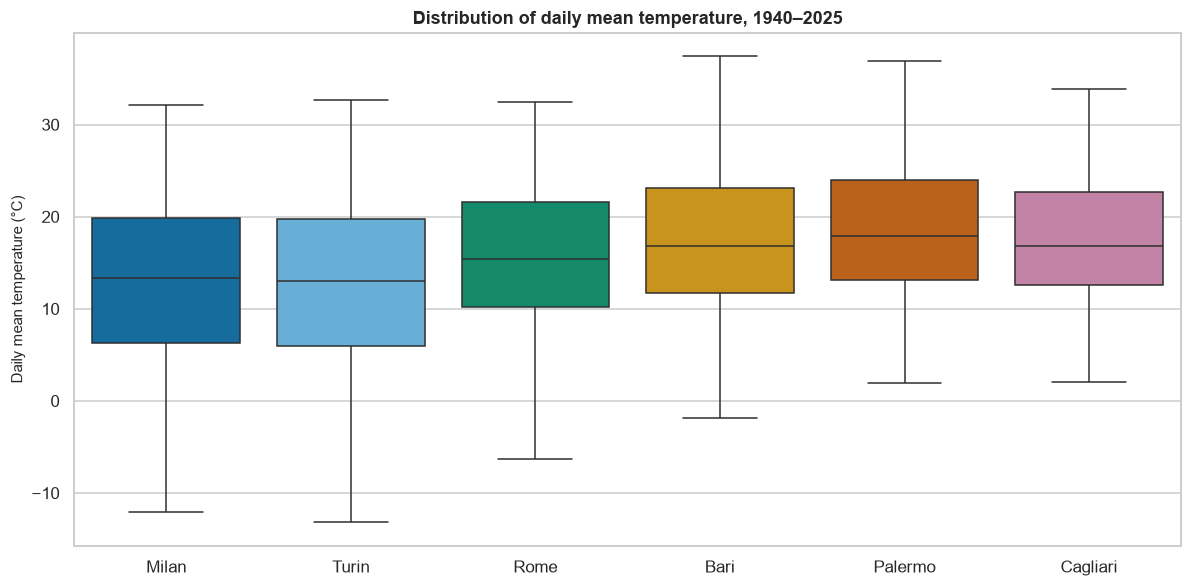

In [28]:
figure = plot_temperature_distributions(weather_features)
figure_path = save_figure(figure, FIGURE_DIR, "01_temperature_distributions.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
display(figure)
plt.close(figure)

The boxplots compare the complete daily distributions rather than only annual averages. Differences in medians and spread provide context for city-specific heat thresholds: the same fixed temperature does not represent the same local rarity everywhere.

## 4. Monthly seasonality and 1961–1990 climate normals

Daily observations are first aggregated by city, year and month. Climate normals are then calculated as the mean of those monthly values during the fixed 1961–1990 reference period.

In [29]:
monthly_summary = calculate_monthly_summary(weather_features)
monthly_climatology = calculate_monthly_climatology(
    monthly_summary,
    baseline_start=BASELINE_START,
    baseline_end=BASELINE_END,
)
monthly_anomalies = calculate_monthly_temperature_anomalies(
    monthly_summary,
    monthly_climatology,
)

print(f"Monthly observations: {len(monthly_summary):,}")
display(monthly_climatology.head(12))

Monthly observations: 6,192


,city,city_slug,month,month_name,baseline_temperature,baseline_precipitation,baseline_years
0,Bari,bari,1,January,9.318602,55.323333,30
1,Bari,bari,2,February,9.886178,64.956667,30
2,Bari,bari,3,March,11.730430,66.500000,30
3,Bari,bari,4,April,14.698444,52.883333,30
4,Bari,bari,5,May,19.031720,45.510000,30
5,Bari,bari,6,June,22.887667,39.060000,30
6,Bari,bari,7,July,25.668495,23.680000,30
7,Bari,bari,8,August,25.450323,34.443333,30
8,Bari,bari,9,September,22.285444,49.740000,30
9,Bari,bari,10,October,18.033011,61.400000,30


Weather-Report/reports/figures/eda/02_monthly_climatology.png


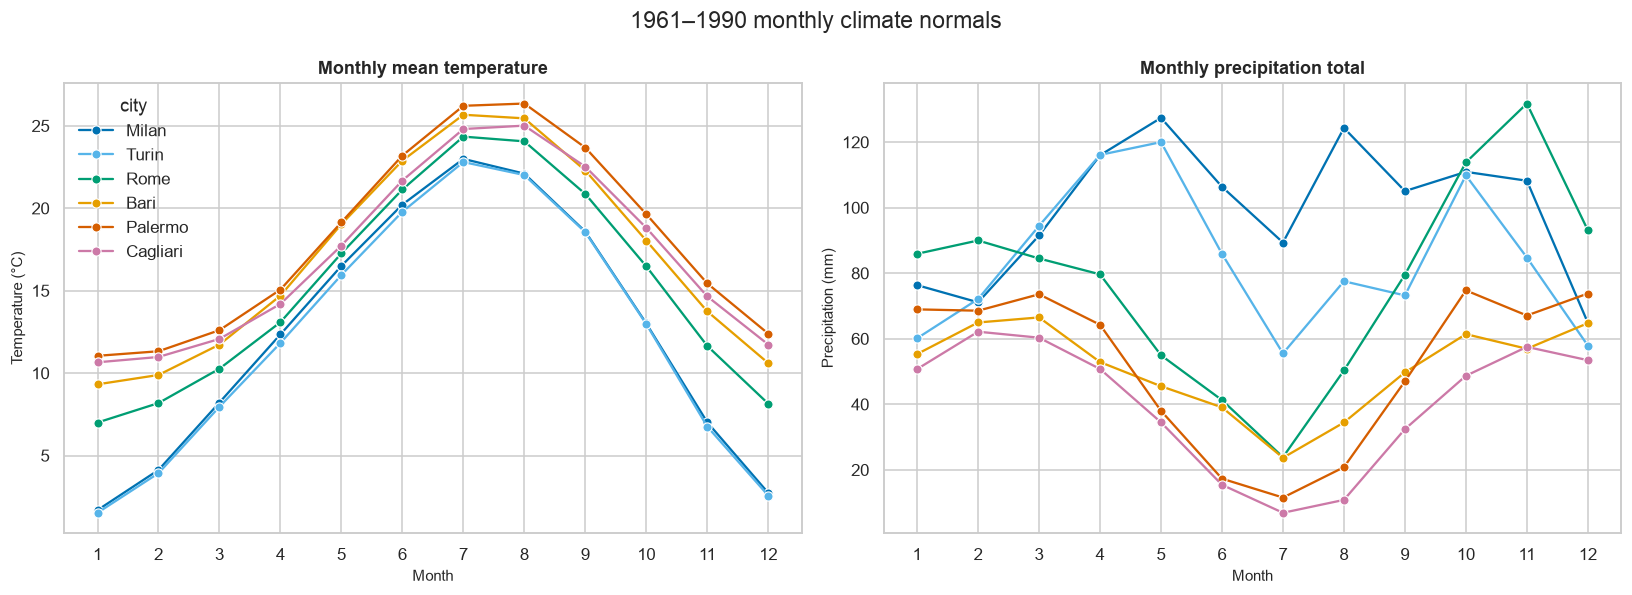

In [30]:
figure = plot_monthly_climatology(monthly_climatology)
figure_path = save_figure(figure, FIGURE_DIR, "02_monthly_climatology.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
display(figure)
plt.close(figure)

This comparison shows both geographical and seasonal structure. Northern cities generally have colder winters and greater annual temperature ranges, while southern and island cities retain milder winter conditions. Precipitation seasonality also differs substantially between cities.

## 5. Annual temperature evolution

Annual indicators include mean temperature and a trailing 10-year average. The rolling average reduces year-to-year weather variability and makes the long-term direction easier to see. It is descriptive and does not replace formal trend inference.

In [31]:
annual_indicators = calculate_annual_indicators(weather_features, rolling_window=10)
annual_indicators = add_annual_temperature_anomalies(
    annual_indicators,
    baseline_start=BASELINE_START,
    baseline_end=BASELINE_END,
)

heat_thresholds, heatwave_indicators = calculate_heatwave_indicators(
    weather_features,
    baseline_start=BASELINE_START,
    baseline_end=BASELINE_END,
    percentile=0.90,
    minimum_duration=3,
)
annual_indicators = merge_annual_indicators(
    annual_indicators,
    heatwave_indicators,
)
temperature_trends = estimate_temperature_trends(annual_indicators)

print(f"Annual city observations: {len(annual_indicators):,}")

Annual city observations: 516


Weather-Report/reports/figures/eda/03_annual_temperature.png


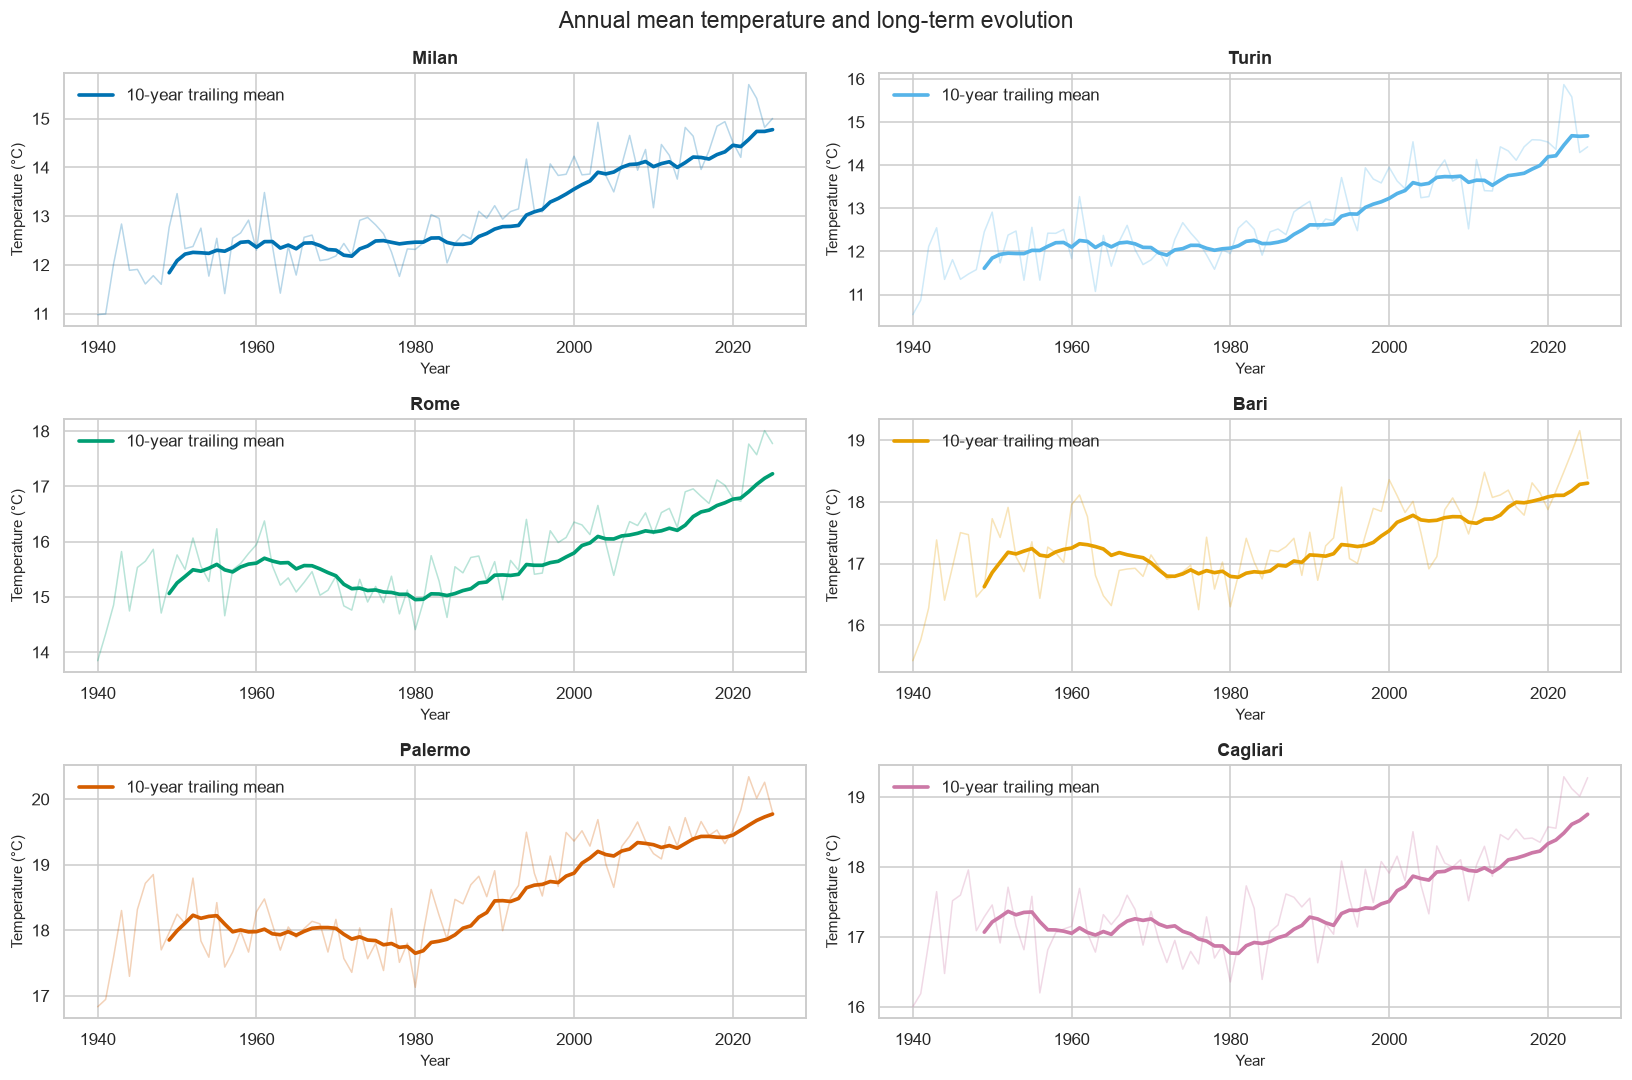

In [32]:
figure = plot_annual_temperature(annual_indicators)
figure_path = save_figure(figure, FIGURE_DIR, "03_annual_temperature.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
display(figure)
plt.close(figure)

## 6. Temperature anomalies

An anomaly is the difference from the city's 1961–1990 mean. Annual anomalies compare whole years with the annual baseline. Monthly anomalies compare each month only with the same calendar month in the baseline, so normal seasonality is removed.

Weather-Report/reports/figures/eda/04_annual_temperature_anomalies.png


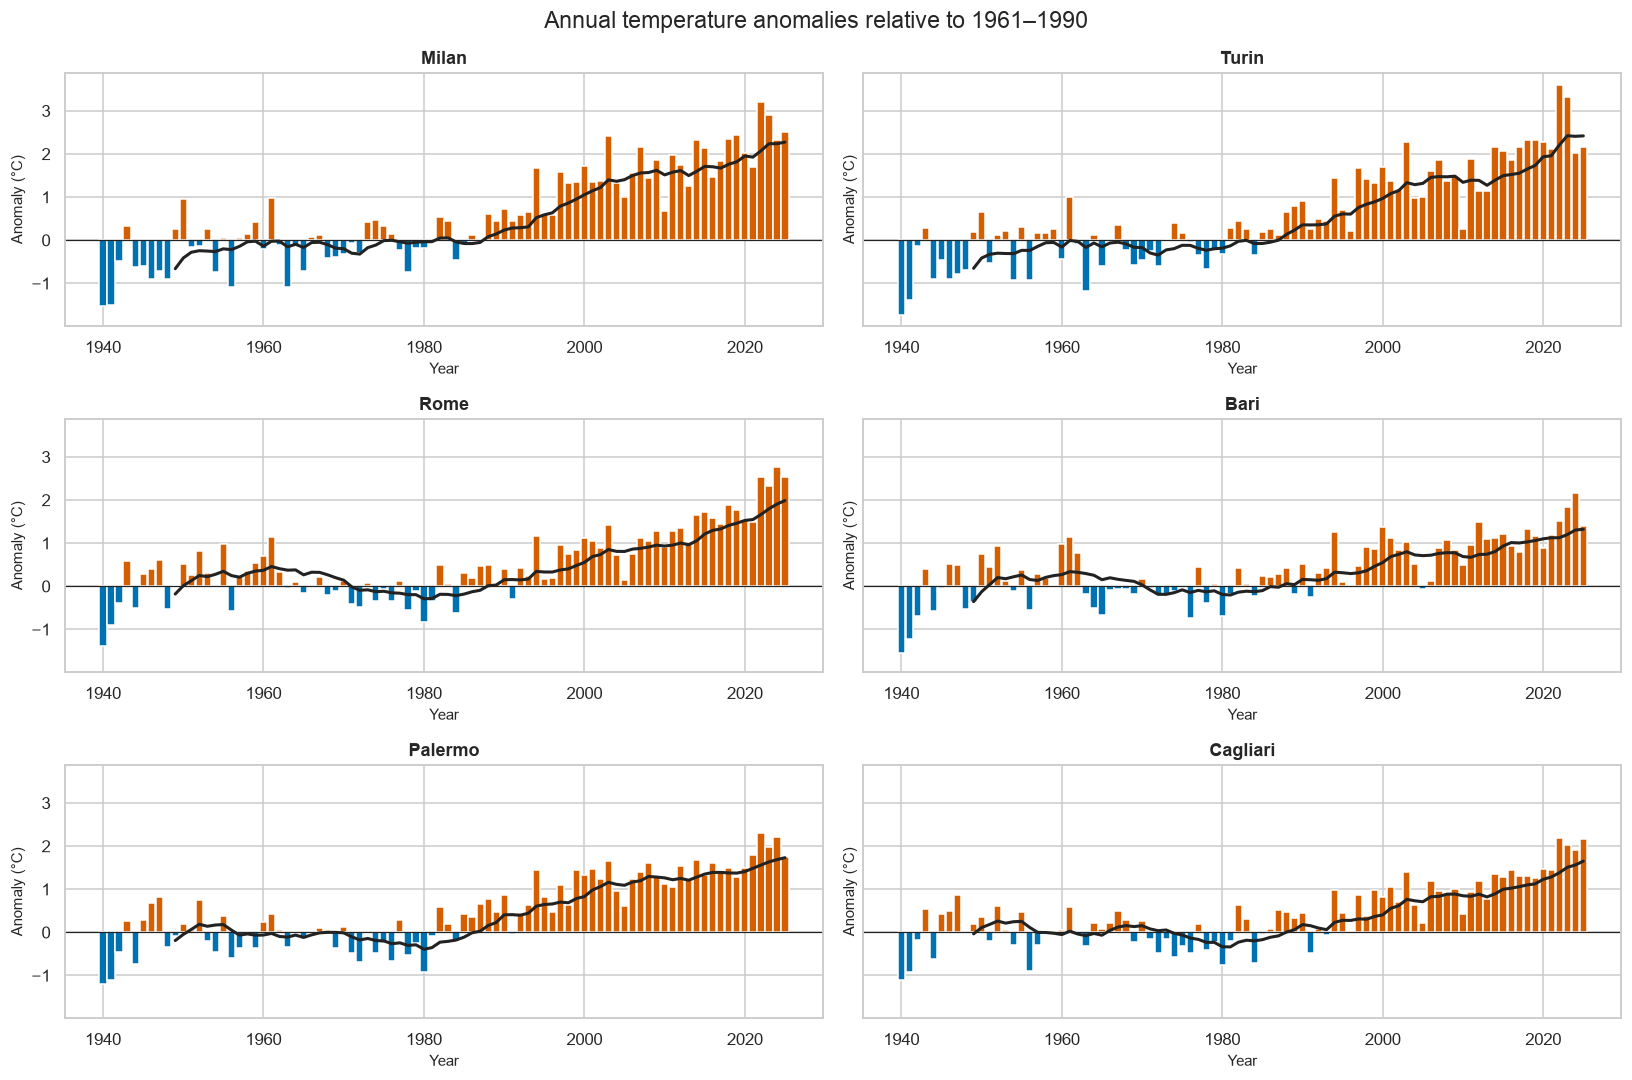

In [33]:
figure = plot_annual_temperature_anomalies(annual_indicators)
figure_path = save_figure(figure, FIGURE_DIR, "04_annual_temperature_anomalies.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
display(figure)
plt.close(figure)

Weather-Report/reports/figures/eda/05_monthly_anomaly_heatmaps.png


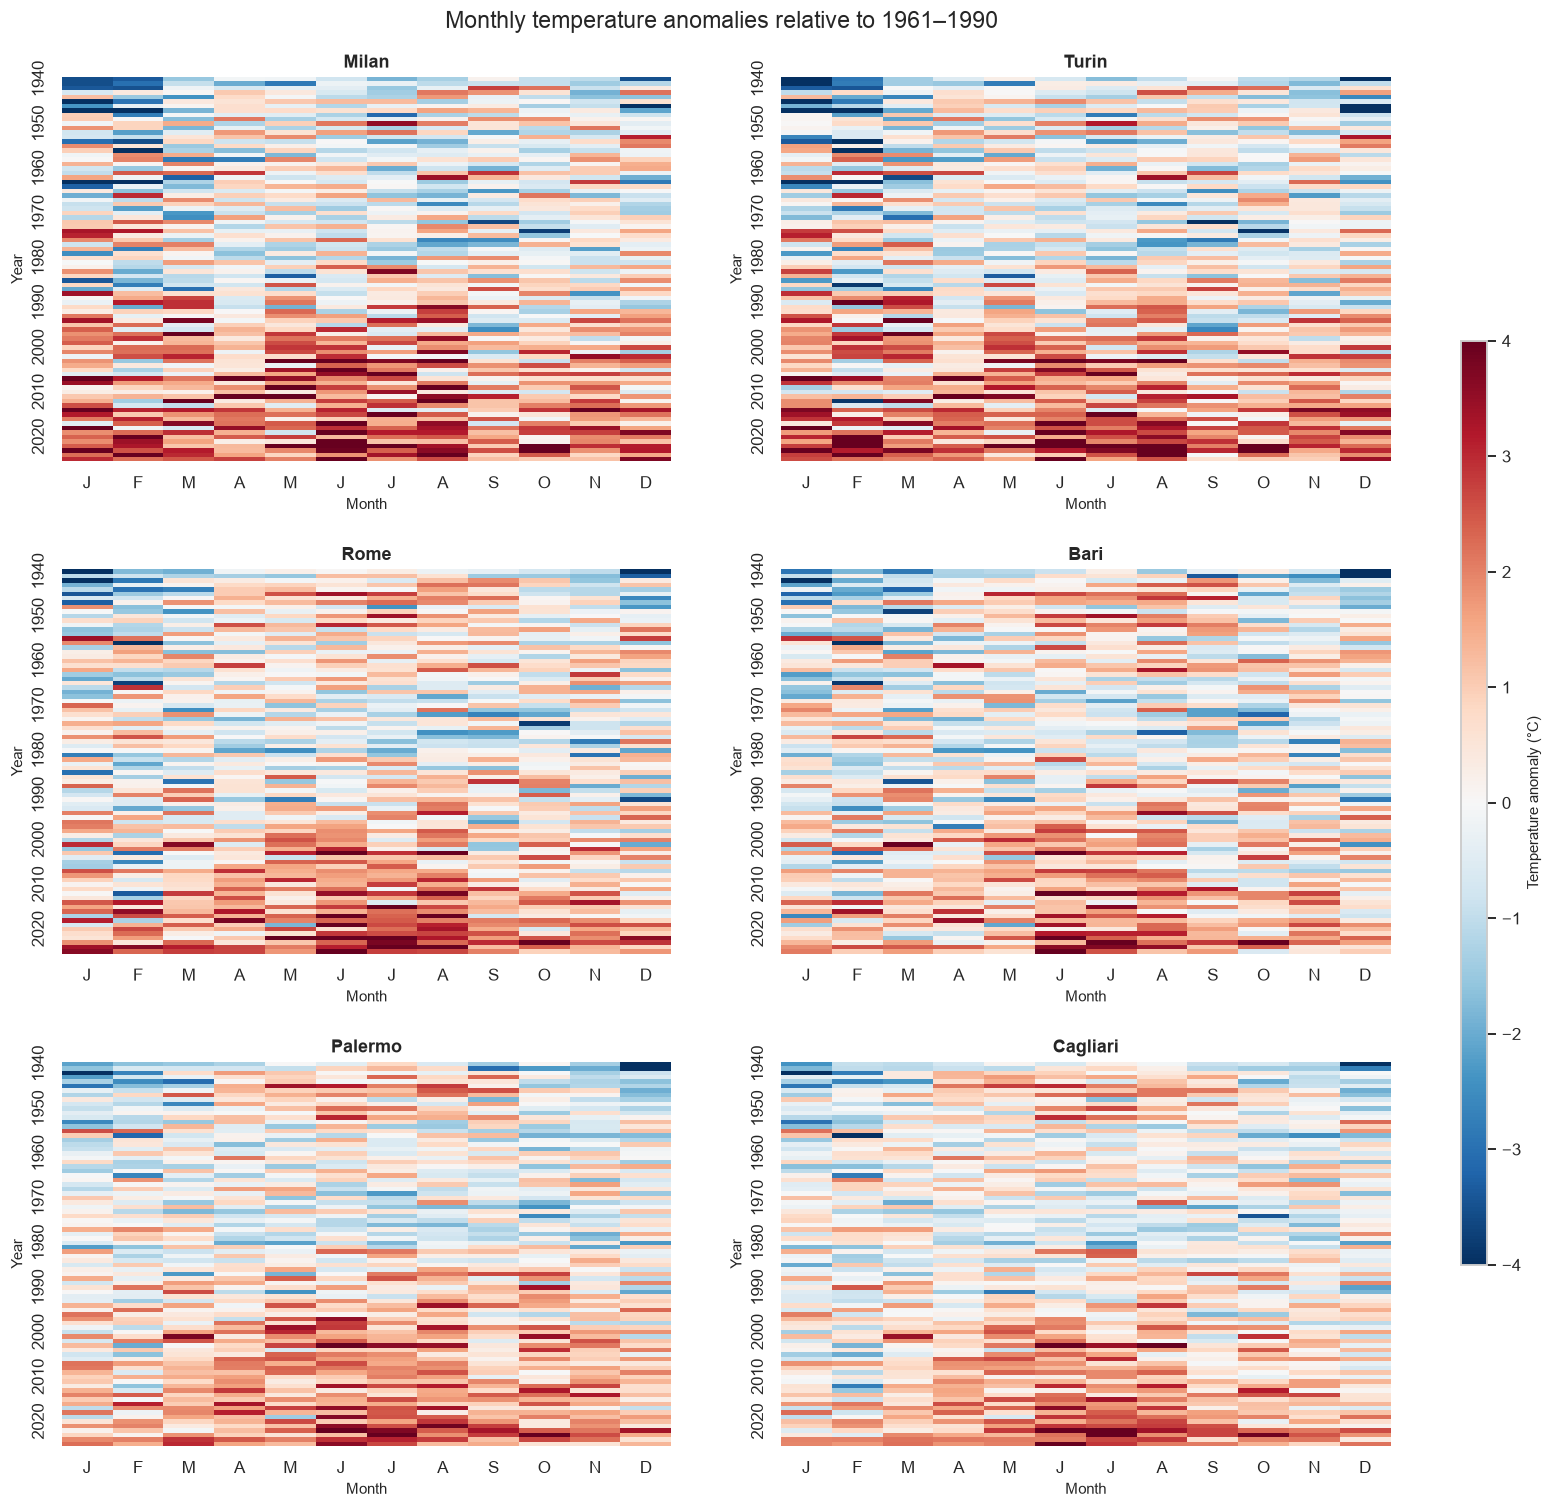

In [34]:
figure = plot_monthly_anomaly_heatmaps(monthly_anomalies)
figure_path = save_figure(figure, FIGURE_DIR, "05_monthly_anomaly_heatmaps.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
display(figure)
plt.close(figure)

The anomaly charts reveal whether warm conditions are isolated events or persist across years and months. A visual shift from predominantly blue to predominantly red cells is evidence of a changing local temperature distribution, though uncertainty and significance are assessed later.

## 7. Exploratory warming rates and city comparison

A simple linear model summarizes the direction and approximate magnitude of change in °C per decade. These slopes are descriptive: the later statistical notebook will add confidence intervals, hypothesis tests and robustness checks.

,city,start_year,end_year,slope_celsius_per_decade,r_squared
0,Milan,1940,2025,0.370,0.735
1,Turin,1940,2025,0.369,0.714
2,Palermo,1940,2025,0.267,0.657
3,Rome,1940,2025,0.234,0.509
4,Cagliari,1940,2025,0.206,0.512
5,Bari,1940,2025,0.186,0.449


Weather-Report/reports/figures/eda/06_temperature_trends.png


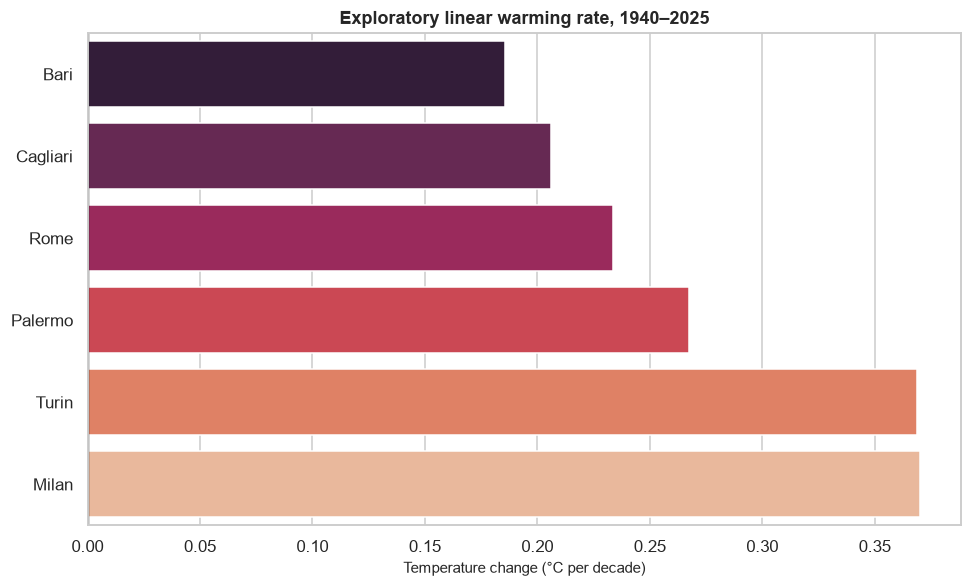

In [35]:
display(
    temperature_trends[[
        "city", "start_year", "end_year",
        "slope_celsius_per_decade", "r_squared",
    ]].round(3)
)

figure = plot_temperature_trends(temperature_trends)
figure_path = save_figure(figure, FIGURE_DIR, "06_temperature_trends.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
display(figure)
plt.close(figure)

## 8. Extreme heat

Three complementary indicators are used:

- **hot day:** maximum temperature at least 30 °C;
- **tropical night:** minimum temperature at least 20 °C;
- **heatwave:** at least three consecutive summer days at or above the city's 90th percentile of summer maximum temperature during 1961–1990.

The relative heatwave threshold makes extremes comparable across cities with different background climates.

,city,city_slug,heat_threshold
0,Bari,bari,33.8
1,Cagliari,cagliari,31.5
2,Milan,milan,31.4
3,Palermo,palermo,34.0
4,Rome,rome,32.8
5,Turin,turin,30.7


Weather-Report/reports/figures/eda/07_extreme_heat_indicators.png


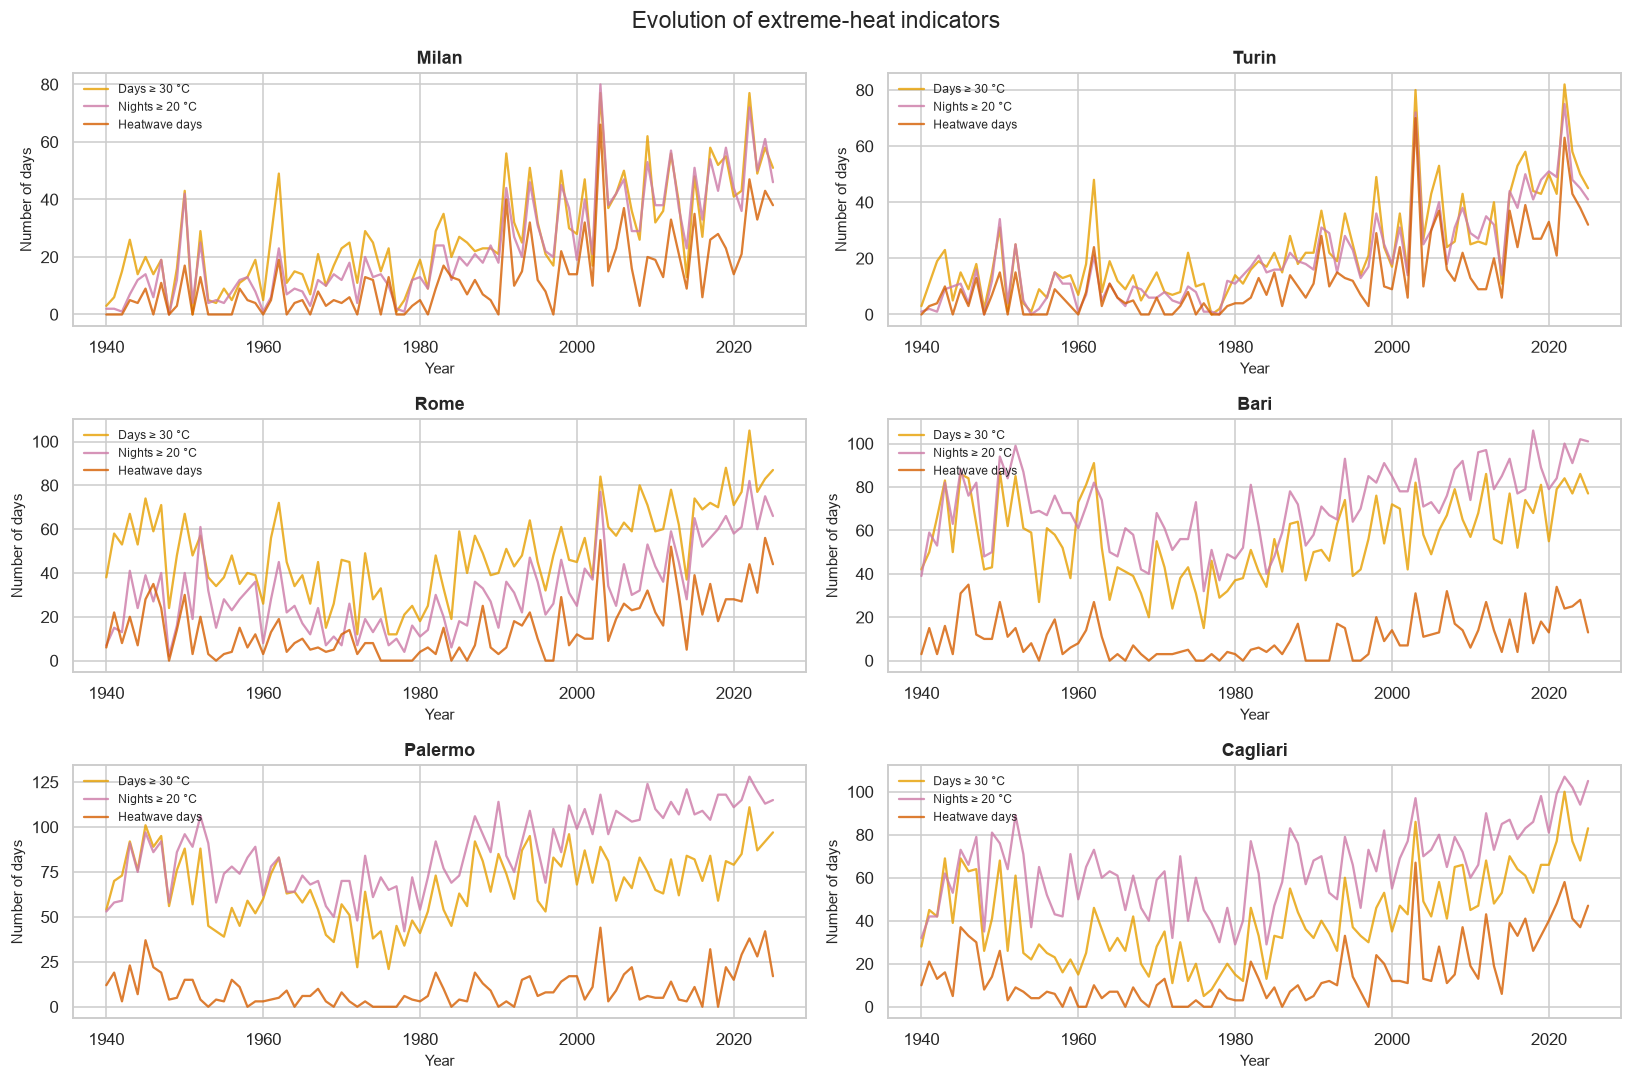

In [36]:
display(heat_thresholds.round({"heat_threshold": 1}))

figure = plot_extreme_heat_indicators(annual_indicators)
figure_path = save_figure(figure, FIGURE_DIR, "07_extreme_heat_indicators.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
display(figure)
plt.close(figure)

## 9. Precipitation patterns

The chart combines annual precipitation totals, their 10-year rolling average and the annual number of days with at least 20 mm. Because precipitation for 1 January 1940 is unavailable, all precipitation indicators for 1940 are set to missing instead of underestimating that year's total.

,city,year,precipitation_missing_days
0,Bari,1940,1
86,Cagliari,1940,1
172,Milan,1940,1
258,Palermo,1940,1
344,Rome,1940,1
430,Turin,1940,1


Weather-Report/reports/figures/eda/08_precipitation_indicators.png


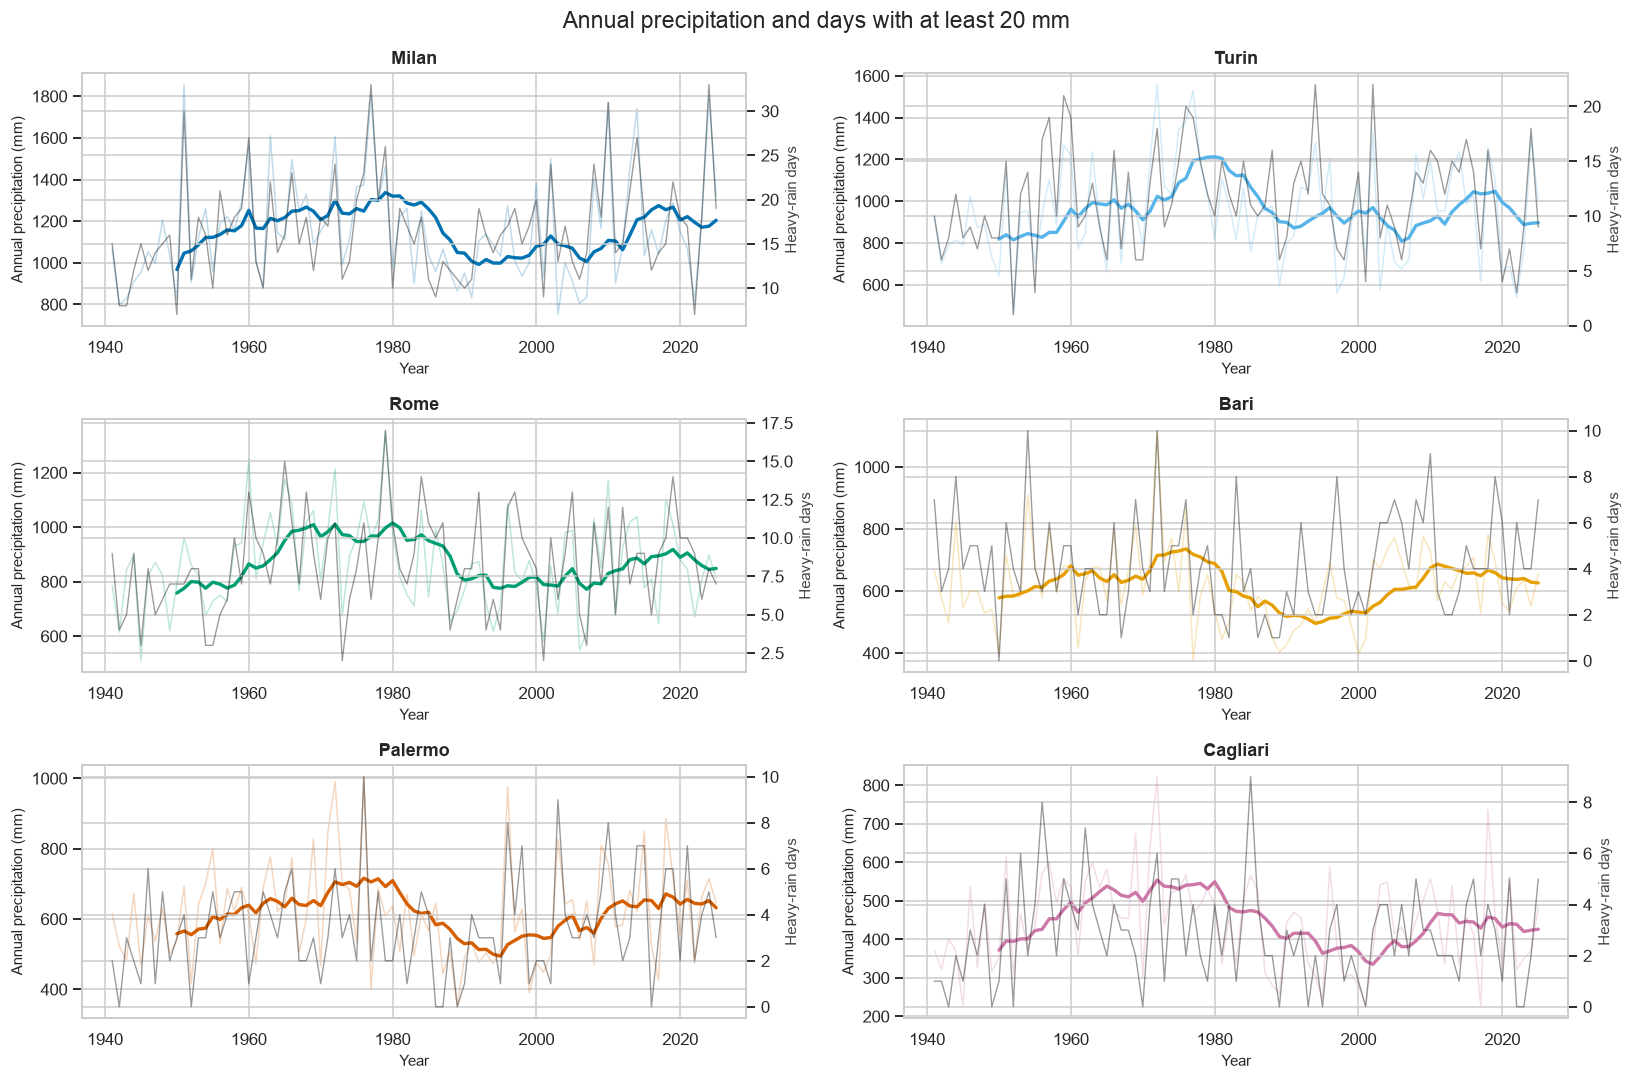

In [37]:
incomplete_precipitation_years = annual_indicators.loc[
    annual_indicators["precipitation_missing_days"] > 0,
    ["city", "year", "precipitation_missing_days"],
]
display(incomplete_precipitation_years)

figure = plot_precipitation_indicators(annual_indicators)
figure_path = save_figure(figure, FIGURE_DIR, "08_precipitation_indicators.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
display(figure)
plt.close(figure)

Temperature trends are usually visually smoother than precipitation trends. Changes in rainfall totals, frequency and event intensity must be considered separately, and local extremes require greater caution because ERA5 represents a grid cell rather than one rain gauge.

## 10. Early-versus-recent climate comparison

Two complete 30-year periods are compared: **1941–1970** and **1996–2025**. The comparison is descriptive and gives each period equal duration. Starting in 1941 also avoids the incomplete precipitation boundary in 1940.

In [38]:
comparison_metrics = [
    "temperature_mean",
    "hot_days",
    "very_hot_days",
    "tropical_nights",
    "heatwave_days",
    "precipitation_total",
    "wet_days",
    "heavy_rain_days",
    "rx1day",
    "wet_day_intensity",
]
period_comparison = compare_climate_periods(
    annual_indicators,
    metrics=comparison_metrics,
    early_period=(1941, 1970),
    recent_period=(1996, 2025),
)

In [39]:
temperature_and_heat_comparison = period_comparison.loc[
    period_comparison["metric"].isin(
        ["temperature_mean", "hot_days", "tropical_nights", "heatwave_days"]
    ),
    ["city", "metric", "early_mean", "recent_mean", "absolute_change", "percentage_change"],
].copy()
display(temperature_and_heat_comparison.round(2))

,city,metric,early_mean,recent_mean,absolute_change,percentage_change
0,Bari,temperature_mean,17.04,17.97,0.93,5.46
1,Bari,hot_days,57.03,66.77,9.73,17.07
3,Bari,tropical_nights,67.87,85.40,17.53,25.83
4,Bari,heatwave_days,10.53,15.73,5.20,49.37
10,Cagliari,temperature_mean,17.17,18.22,1.05,6.11
11,Cagliari,hot_days,36.17,58.00,21.83,60.37
13,Cagliari,tropical_nights,58.87,79.83,20.97,35.62
14,Cagliari,heatwave_days,10.07,27.07,17.00,168.87
20,Milan,temperature_mean,12.25,14.30,2.05,16.71
21,Milan,hot_days,15.57,42.50,26.93,173.02


In [40]:
precipitation_comparison = period_comparison.loc[
    period_comparison["metric"].isin(
        ["precipitation_total", "wet_days", "heavy_rain_days", "rx1day", "wet_day_intensity"]
    ),
    ["city", "metric", "early_mean", "recent_mean", "absolute_change", "percentage_change"],
].copy()
display(precipitation_comparison.round(2))

,city,metric,early_mean,recent_mean,absolute_change,percentage_change
5,Bari,precipitation_total,632.50,629.46,-3.05,-0.48
6,Bari,wet_days,102.30,98.33,-3.97,-3.88
7,Bari,heavy_rain_days,4.27,4.73,0.47,10.94
8,Bari,rx1day,39.46,38.55,-0.91,-2.31
9,Bari,wet_day_intensity,6.18,6.43,0.25,4.09
15,Cagliari,precipitation_total,455.49,423.26,-32.22,-7.07
16,Cagliari,wet_days,77.17,70.30,-6.87,-8.90
17,Cagliari,heavy_rain_days,2.90,2.63,-0.27,-9.20
18,Cagliari,rx1day,33.26,31.65,-1.61,-4.84
19,Cagliari,wet_day_intensity,5.85,5.99,0.14,2.43


## 11. Notable years and concise findings

In [41]:
warmest_years = (
    annual_indicators.sort_values(
        ["city_slug", "temperature_mean"], ascending=[True, False]
    )
    .groupby("city_slug", observed=True)
    .head(3)
    [["city", "year", "temperature_mean", "temperature_anomaly"]]
    .sort_values(["city", "temperature_mean"], ascending=[True, False])
)

wettest_years = (
    annual_indicators.dropna(subset=["precipitation_total"])
    .sort_values(["city_slug", "precipitation_total"], ascending=[True, False])
    .groupby("city_slug", observed=True)
    .head(3)
    [["city", "year", "precipitation_total", "rx1day"]]
    .sort_values(["city", "precipitation_total"], ascending=[True, False])
)

print("Three warmest years by city")
display(warmest_years.round(2))
print("Three wettest complete years by city")
display(wettest_years.round(2))

Three warmest years by city


,city,year,temperature_mean,temperature_anomaly
84,Bari,2024,19.16,2.17
83,Bari,2023,18.81,1.83
82,Bari,2022,18.49,1.51
168,Cagliari,2022,19.29,2.19
171,Cagliari,2025,19.28,2.17
169,Cagliari,2023,19.12,2.02
254,Milan,2022,15.70,3.20
255,Milan,2023,15.41,2.91
257,Milan,2025,15.00,2.50
340,Palermo,2022,20.34,2.30


Three wettest complete years by city


,city,year,precipitation_total,rx1day
32,Bari,1972,1117.4,56.1
14,Bari,1954,909.3,56.6
36,Bari,1976,865.1,40.0
118,Cagliari,1972,822.3,40.8
164,Cagliari,2018,737.5,44.2
115,Cagliari,1969,675.9,45.5
183,Milan,1951,1855.9,96.9
209,Milan,1977,1804.4,65.7
256,Milan,2024,1791.6,62.7
294,Palermo,1976,1004.7,63.5


In [42]:
print("Exploratory temperature findings:")
for row in temperature_trends.itertuples(index=False):
    recent_anomaly = annual_indicators.loc[
        (annual_indicators["city_slug"] == row.city_slug)
        & annual_indicators["year"].between(1996, 2025),
        "temperature_anomaly",
    ].mean()
    print(
        f"- {row.city}: {row.slope_celsius_per_decade:.2f} °C/decade; "
        f"mean 1996–2025 anomaly {recent_anomaly:+.2f} °C."
    )

print("\nThese descriptive findings motivate formal uncertainty and significance tests; "
      "they are not causal attribution claims.")

Exploratory temperature findings:
- Milan: 0.37 °C/decade; mean 1996–2025 anomaly +1.80 °C.
- Turin: 0.37 °C/decade; mean 1996–2025 anomaly +1.74 °C.
- Palermo: 0.27 °C/decade; mean 1996–2025 anomaly +1.39 °C.
- Rome: 0.23 °C/decade; mean 1996–2025 anomaly +1.34 °C.
- Cagliari: 0.21 °C/decade; mean 1996–2025 anomaly +1.12 °C.
- Bari: 0.19 °C/decade; mean 1996–2025 anomaly +0.99 °C.

These descriptive findings motivate formal uncertainty and significance tests; they are not causal attribution claims.


## 12. Save derived tables

These tables make the next statistical notebook reproducible without repeating all EDA calculations. Raw and cleaned daily data remain unchanged.

In [43]:
derived_outputs = {
    "monthly_climate_summary.csv": monthly_summary,
    "monthly_temperature_anomalies.csv": monthly_anomalies,
    "annual_climate_indicators.csv": annual_indicators,
    "heatwave_thresholds.csv": heat_thresholds,
    "temperature_trends_exploratory.csv": temperature_trends,
    "period_comparison_1941_1970_vs_1996_2025.csv": period_comparison,
}

for filename, dataframe in derived_outputs.items():
    output_path = DERIVED_DATA_DIR / filename
    dataframe.to_csv(output_path, index=False, date_format="%Y-%m-%d")
    display_path = Path(PROJECT_ROOT.name) / output_path.relative_to(PROJECT_ROOT)
    print(f"Saved {len(dataframe):,} rows: {display_path}")

Saved 6,192 rows: Weather-Report/data/processed/monthly_climate_summary.csv
Saved 6,192 rows: Weather-Report/data/processed/monthly_temperature_anomalies.csv
Saved 516 rows: Weather-Report/data/processed/annual_climate_indicators.csv
Saved 6 rows: Weather-Report/data/processed/heatwave_thresholds.csv
Saved 6 rows: Weather-Report/data/processed/temperature_trends_exploratory.csv
Saved 60 rows: Weather-Report/data/processed/period_comparison_1941_1970_vs_1996_2025.csv


## EDA checkpoint

The EDA provides evidence of long-term warming, increasingly positive anomalies and changes in several heat indicators across the selected cities. Rainfall behavior is more variable and must be interpreted through separate measures of total amount, frequency and intensity.

The following sections extend the same notebook from descriptive exploration to statistical trend estimation. They quantify uncertainty and distinguish visually compelling patterns from statistically supported conclusions.

# Statistical extension

The models below use ordinary least squares with 95% confidence intervals. Individual time-series trends use Newey–West HAC standard errors with one lag to reduce sensitivity to short-range autocorrelation and changing residual variance. The pooled city-by-year model uses HC3 robust covariance.

Statistical significance is summarized as `***` for p < 0.001, `**` for p < 0.01 and `*` for p < 0.05. Effect size and confidence intervals remain more informative than symbols alone.

## 13. Annual temperature trends with confidence intervals

A separate model is fitted for every city:

```text
annual mean temperature = intercept + slope × year
```

The slope is reported in °C per decade together with its HAC 95% confidence interval.

In [44]:
annual_temperature_trends = add_significance_labels(
    fit_grouped_linear_trends(
        annual_indicators,
        value_column="temperature_mean",
        confidence_level=0.95,
        hac_lags=1,
    )
)
annual_temperature_table = annual_temperature_trends[[
    "city", "slope_per_decade", "ci_lower_per_decade",
    "ci_upper_per_decade", "p_value", "r_squared", "significance",
]].copy()
annual_temperature_table["p_value"] = annual_temperature_table["p_value"].map(
    lambda value: f"{value:.3g}"
)
display(annual_temperature_table.round(3))

,city,slope_per_decade,ci_lower_per_decade,ci_upper_per_decade,p_value,r_squared,significance
0,Bari,0.186,0.128,0.243,2.93e-10,0.449,***
1,Cagliari,0.206,0.150,0.262,3.95e-13,0.512,***
2,Milan,0.370,0.315,0.425,1.63e-39,0.735,***
3,Palermo,0.267,0.217,0.317,9.61e-26,0.657,***
4,Rome,0.234,0.168,0.299,3.47e-12,0.509,***
5,Turin,0.369,0.307,0.431,1.27e-31,0.714,***


Weather-Report/reports/figures/eda/09_annual_temperature_trend_intervals.png


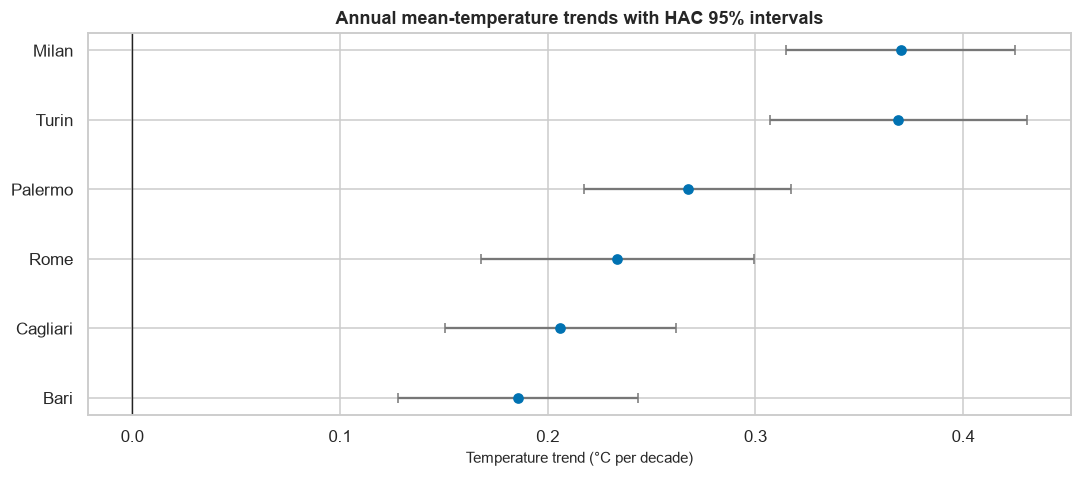

In [45]:
figure = plot_trend_intervals(
    annual_temperature_trends,
    label_column="city",
    title="Annual mean-temperature trends with HAC 95% intervals",
    x_label="Temperature trend (°C per decade)",
)
figure_path = save_figure(figure, FIGURE_DIR, "09_annual_temperature_trend_intervals.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
display(figure)
plt.close(figure)

A confidence interval entirely above zero supports a positive long-term trend for that city. The interval communicates both direction and estimation uncertainty.

## 14. Seasonal temperature trends

Daily observations are aggregated into complete meteorological seasons. Partial boundary winters are excluded. Separate city-and-season regressions show whether warming is uniform across the calendar year.

In [46]:
seasonal_indicators = calculate_seasonal_indicators(weather_features)
seasonal_temperature_trends = add_significance_labels(
    fit_grouped_linear_trends(
        seasonal_indicators,
        value_column="temperature_mean",
        group_columns=("city", "city_slug", "season"),
        confidence_level=0.95,
        hac_lags=1,
    )
)
seasonal_table = seasonal_temperature_trends[[
    "city", "season", "slope_per_decade",
    "ci_lower_per_decade", "ci_upper_per_decade",
    "p_value", "significance",
]].copy()
seasonal_table["p_value"] = seasonal_table["p_value"].map(lambda value: f"{value:.3g}")
display(seasonal_table.round(3))

,city,season,slope_per_decade,ci_lower_per_decade,ci_upper_per_decade,p_value,significance
0,Bari,Winter,0.203,0.107,0.299,3.16e-05,***
1,Bari,Spring,0.168,0.100,0.236,1.2e-06,***
2,Bari,Summer,0.212,0.106,0.318,9.06e-05,***
3,Bari,Autumn,0.151,0.069,0.234,0.000308,***
4,Cagliari,Winter,0.196,0.116,0.276,1.53e-06,***
5,Cagliari,Spring,0.169,0.104,0.235,4.31e-07,***
6,Cagliari,Summer,0.249,0.145,0.353,2.88e-06,***
7,Cagliari,Autumn,0.201,0.128,0.274,6.41e-08,***
8,Milan,Winter,0.442,0.320,0.564,1.19e-12,***
9,Milan,Spring,0.315,0.253,0.377,1.9e-23,***


Weather-Report/reports/figures/eda/10_seasonal_temperature_trends.png


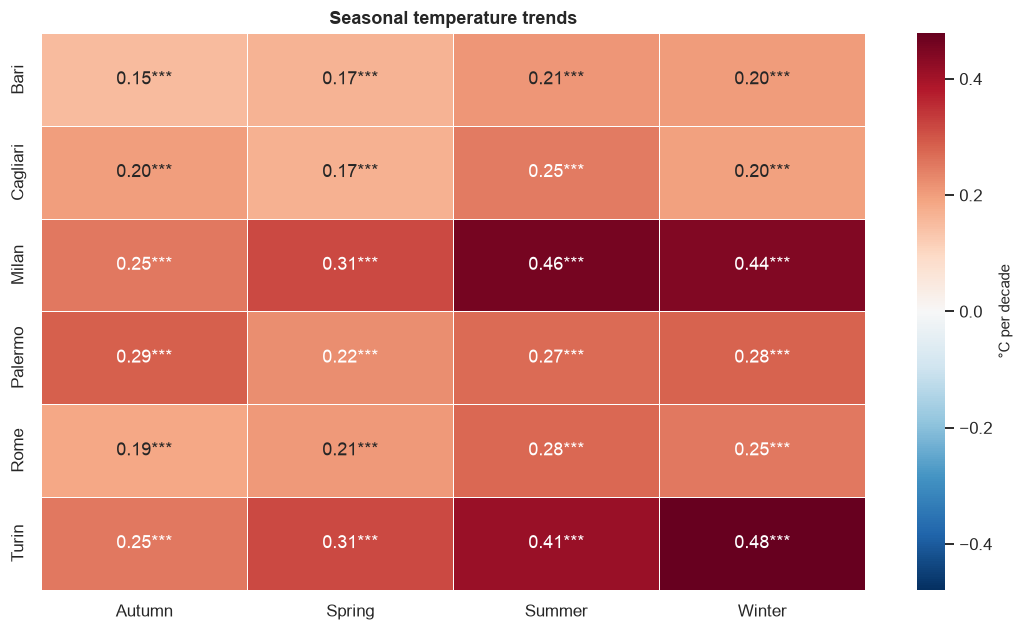

In [47]:
figure = plot_trend_heatmap(
    seasonal_temperature_trends,
    row_column="city",
    column_column="season",
    title="Seasonal temperature trends",
    colorbar_label="°C per decade",
)
figure_path = save_figure(figure, FIGURE_DIR, "10_seasonal_temperature_trends.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
display(figure)
plt.close(figure)

## 15. Minimum versus maximum temperature

Annual means of daily minimum and maximum temperature are modelled separately. The mean daily temperature range is also tested to see whether nights and days are changing at different rates.

In [48]:
temperature_component_labels = {
    "temperature_min_mean": "Daily minimum",
    "temperature_max_mean": "Daily maximum",
    "diurnal_temperature_range": "Daily range",
}
temperature_component_results = []
for metric, label in temperature_component_labels.items():
    result = fit_grouped_linear_trends(annual_indicators, value_column=metric)
    result["temperature_component"] = label
    temperature_component_results.append(result)

temperature_component_trends = add_significance_labels(
    pd.concat(temperature_component_results, ignore_index=True)
)
display(temperature_component_trends[[
    "city", "temperature_component", "slope_per_decade",
    "ci_lower_per_decade", "ci_upper_per_decade",
    "p_value", "significance",
]].round(3))

,city,temperature_component,slope_per_decade,ci_lower_per_decade,ci_upper_per_decade,p_value,significance
0,Bari,Daily minimum,0.189,0.131,0.248,0.000,***
1,Cagliari,Daily minimum,0.163,0.108,0.218,0.000,***
2,Milan,Daily minimum,0.422,0.369,0.474,0.000,***
3,Palermo,Daily minimum,0.317,0.264,0.369,0.000,***
4,Rome,Daily minimum,0.224,0.151,0.296,0.000,***
5,Turin,Daily minimum,0.403,0.347,0.459,0.000,***
6,Bari,Daily maximum,0.155,0.083,0.227,0.000,***
7,Cagliari,Daily maximum,0.247,0.174,0.320,0.000,***
8,Milan,Daily maximum,0.367,0.299,0.435,0.000,***
9,Palermo,Daily maximum,0.190,0.126,0.255,0.000,***


Weather-Report/reports/figures/eda/11_minimum_maximum_temperature_trends.png


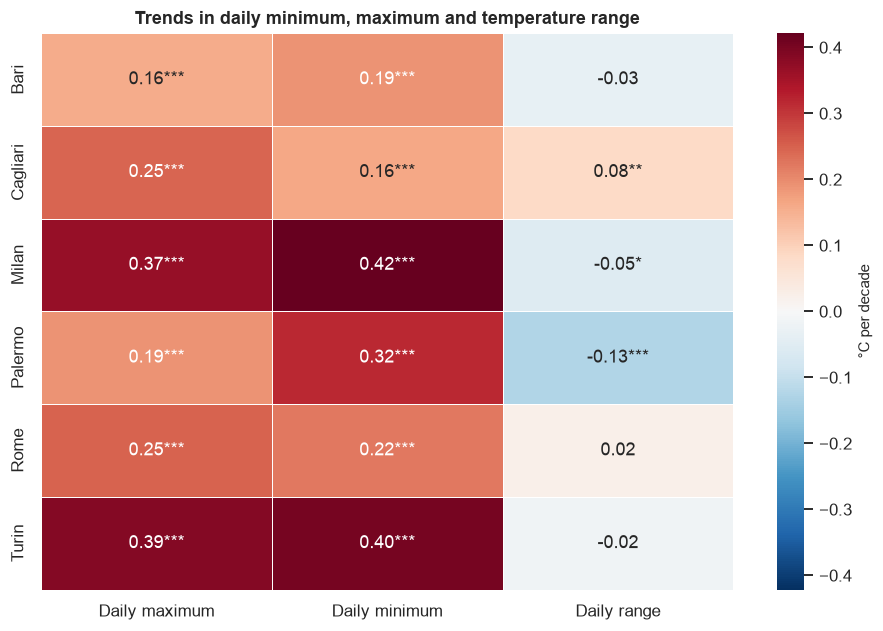

In [49]:
figure = plot_trend_heatmap(
    temperature_component_trends,
    row_column="city",
    column_column="temperature_component",
    title="Trends in daily minimum, maximum and temperature range",
    colorbar_label="°C per decade",
)
figure_path = save_figure(figure, FIGURE_DIR, "11_minimum_maximum_temperature_trends.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
display(figure)
plt.close(figure)

A positive trend in the daily range means maximum temperature is increasing faster than minimum temperature. A negative trend means nights are warming faster than days.

## 16. City-by-year interaction model

The pooled model estimates city intercepts and city-specific time slopes in one regression. Milan is the reference city. Each interaction tests whether another city's warming rate differs from Milan's rate. HC3 robust covariance is used for the confidence intervals.

In [50]:
city_interaction = fit_city_year_interaction(
    annual_indicators,
    value_column="temperature_mean",
    reference_city_slug="milan",
    confidence_level=0.95,
)
print(city_interaction.diagnostics)
print("City-specific slopes")
display(city_interaction.city_slopes.round(3))
print("Slope differences relative to Milan")
display(city_interaction.interaction_effects.round(3))

{'response': 'temperature_mean', 'reference_city_slug': 'milan', 'observations': 516, 'r_squared': 0.9493487885984789, 'adjusted_r_squared': 0.9482433058099536, 'covariance_type': 'HC3'}
City-specific slopes


,city,city_slug,reference_city_slug,slope_per_decade,ci_lower_per_decade,ci_upper_per_decade,p_value
0,Milan,milan,milan,0.370,0.319,0.421,0.0
1,Bari,bari,milan,0.186,0.136,0.235,0.0
2,Cagliari,cagliari,milan,0.206,0.158,0.254,0.0
3,Palermo,palermo,milan,0.267,0.224,0.310,0.0
4,Rome,rome,milan,0.234,0.178,0.289,0.0
5,Turin,turin,milan,0.369,0.312,0.425,0.0


Slope differences relative to Milan


,city,city_slug,reference_city_slug,slope_difference_per_decade,ci_lower_per_decade,ci_upper_per_decade,p_value
0,Bari,bari,milan,-0.184,-0.255,-0.114,0.000
1,Cagliari,cagliari,milan,-0.164,-0.234,-0.094,0.000
2,Palermo,palermo,milan,-0.103,-0.169,-0.036,0.002
3,Rome,rome,milan,-0.136,-0.211,-0.061,0.000
4,Turin,turin,milan,-0.001,-0.077,0.075,0.975


Weather-Report/reports/figures/eda/12_city_year_interaction_slopes.png


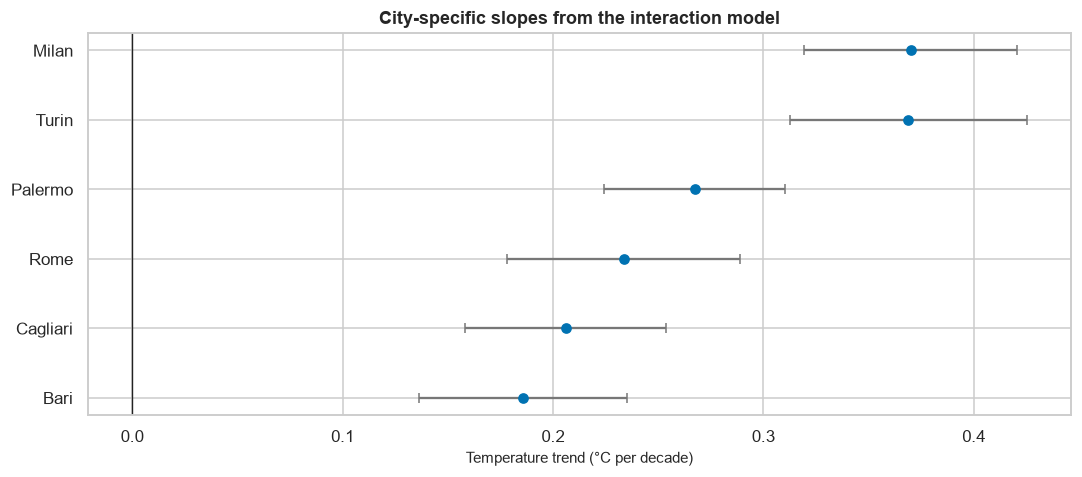

In [51]:
figure = plot_trend_intervals(
    city_interaction.city_slopes,
    label_column="city",
    title="City-specific slopes from the interaction model",
    x_label="Temperature trend (°C per decade)",
)
figure_path = save_figure(figure, FIGURE_DIR, "12_city_year_interaction_slopes.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
display(figure)
plt.close(figure)

A significant interaction indicates a different rate of change, not merely a different average climate. Non-significant interaction terms mean the available data do not distinguish that city's slope from Milan's slope.

## 17. Trends in extreme-heat indicators

Separate annual regressions are fitted to hot days, very hot days, tropical nights, total heatwave days and maximum heatwave duration. Slopes are expressed as additional days per decade.

In [52]:
heat_metric_labels = {
    "hot_days": "Days ≥ 30 °C",
    "very_hot_days": "Days ≥ 35 °C",
    "tropical_nights": "Nights ≥ 20 °C",
    "heatwave_days": "Heatwave days",
    "maximum_heatwave_duration": "Maximum heatwave duration",
}
heat_trend_results = []
for metric, label in heat_metric_labels.items():
    result = fit_grouped_linear_trends(annual_indicators, value_column=metric)
    result["indicator"] = label
    heat_trend_results.append(result)

extreme_heat_trends = add_significance_labels(
    pd.concat(heat_trend_results, ignore_index=True)
)
display(extreme_heat_trends[[
    "city", "indicator", "slope_per_decade",
    "ci_lower_per_decade", "ci_upper_per_decade",
    "p_value", "significance",
]].round(3))

,city,indicator,slope_per_decade,ci_lower_per_decade,ci_upper_per_decade,p_value,significance
0,Bari,Days ≥ 30 °C,1.776,-0.005,3.556,0.051,
1,Cagliari,Days ≥ 30 °C,3.879,1.738,6.020,0.000,***
2,Milan,Days ≥ 30 °C,4.978,3.944,6.011,0.000,***
3,Palermo,Days ≥ 30 °C,2.357,0.474,4.240,0.014,*
4,Rome,Days ≥ 30 °C,3.608,1.679,5.538,0.000,***
5,Turin,Days ≥ 30 °C,4.789,3.541,6.037,0.000,***
6,Bari,Days ≥ 35 °C,0.676,-0.186,1.537,0.124,
7,Cagliari,Days ≥ 35 °C,0.493,0.175,0.812,0.002,**
8,Milan,Days ≥ 35 °C,0.936,0.614,1.259,0.000,***
9,Palermo,Days ≥ 35 °C,0.942,-0.013,1.896,0.053,


Weather-Report/reports/figures/eda/13_extreme_heat_trends.png


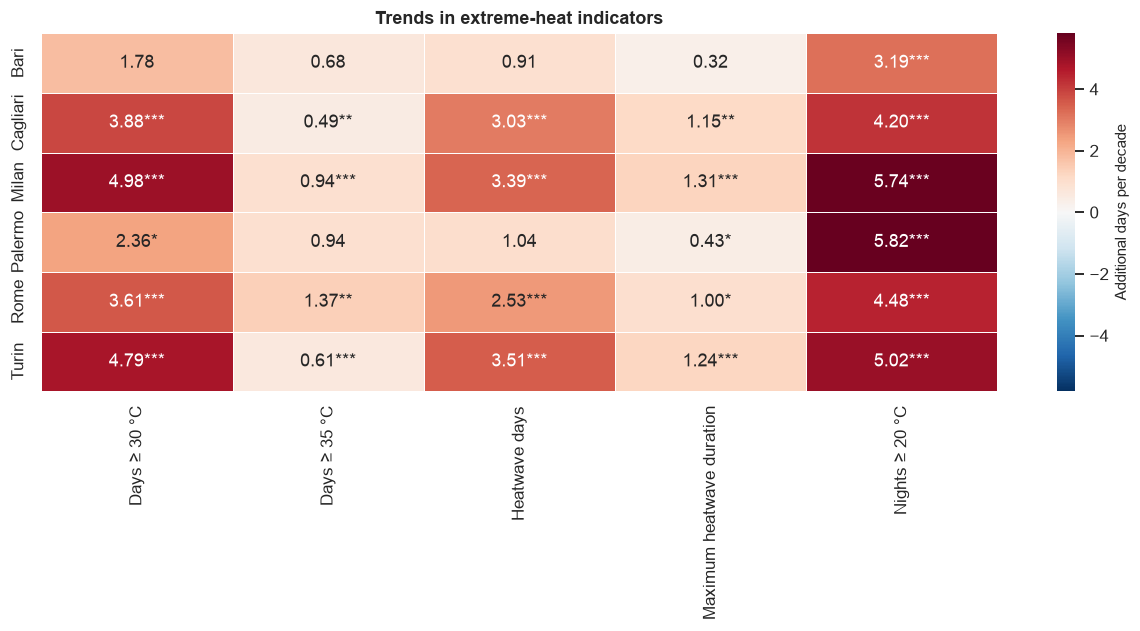

In [53]:
figure = plot_trend_heatmap(
    extreme_heat_trends,
    row_column="city",
    column_column="indicator",
    title="Trends in extreme-heat indicators",
    colorbar_label="Additional days per decade",
)
figure_path = save_figure(figure, FIGURE_DIR, "13_extreme_heat_trends.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
display(figure)
plt.close(figure)

Count outcomes are modelled here with linear trends for consistency and interpretability. The results describe average changes in days per decade; they should not be interpreted as forecasts.

## 18. Rainfall amount, frequency and intensity

Rainfall is separated into three concepts:

- **amount:** annual precipitation total;
- **frequency:** wet days and days with at least 20 mm;
- **intensity:** maximum one-day precipitation and mean precipitation per wet day.

Models begin effectively in 1941 because the incomplete 1940 precipitation indicators are missing.

In [54]:
rain_metric_labels = {
    "precipitation_total": "Annual total",
    "wet_days": "Wet days",
    "heavy_rain_days": "Days ≥ 20 mm",
    "rx1day": "Maximum one-day rain",
    "wet_day_intensity": "Mean rain per wet day",
}
rain_trend_results = []
for metric, label in rain_metric_labels.items():
    result = fit_grouped_linear_trends(annual_indicators, value_column=metric)
    result["indicator"] = label
    rain_trend_results.append(result)

rainfall_trends = add_significance_labels(
    pd.concat(rain_trend_results, ignore_index=True)
)
display(rainfall_trends[[
    "city", "indicator", "slope_per_decade",
    "ci_lower_per_decade", "ci_upper_per_decade",
    "p_value", "significance",
]].round(3))

,city,indicator,slope_per_decade,ci_lower_per_decade,ci_upper_per_decade,p_value,significance
0,Bari,Annual total,-2.080,-11.046,6.886,0.649,
1,Cagliari,Annual total,-5.059,-14.964,4.847,0.317,
2,Milan,Annual total,7.715,-15.700,31.130,0.518,
3,Palermo,Annual total,1.919,-7.420,11.258,0.687,
4,Rome,Annual total,-0.150,-14.306,14.005,0.983,
5,Turin,Annual total,3.419,-16.871,23.709,0.741,
6,Bari,Wet days,-0.630,-1.838,0.577,0.306,
7,Cagliari,Wet days,-1.272,-2.544,0.000,0.050,
8,Milan,Wet days,-0.100,-1.777,1.577,0.907,
9,Palermo,Wet days,-2.056,-3.299,-0.814,0.001,**


Weather-Report/reports/figures/eda/14_annual_precipitation_trend_intervals.png


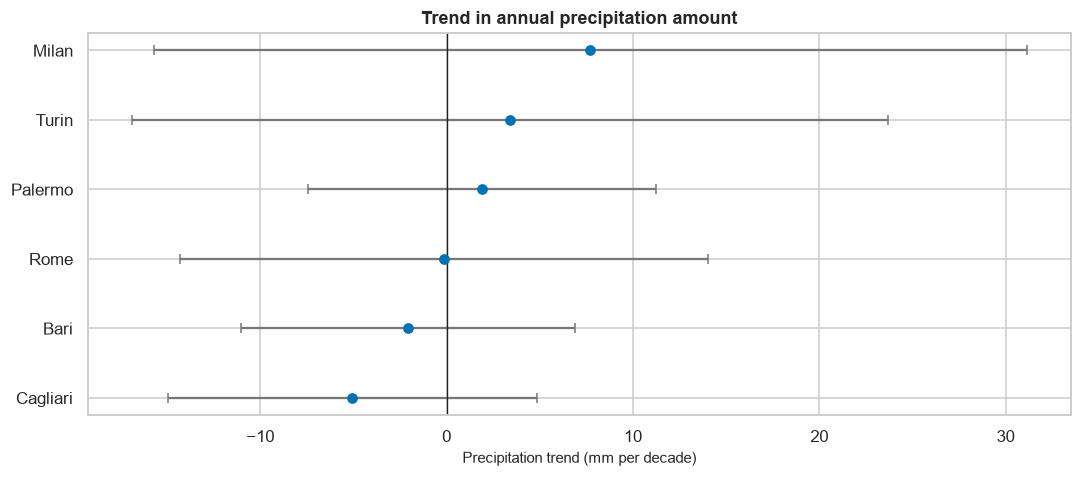

In [55]:
rainfall_amount = rainfall_trends.loc[
    rainfall_trends["metric"] == "precipitation_total"
].copy()
figure = plot_trend_intervals(
    rainfall_amount,
    label_column="city",
    title="Trend in annual precipitation amount",
    x_label="Precipitation trend (mm per decade)",
)
figure_path = save_figure(figure, FIGURE_DIR, "14_annual_precipitation_trend_intervals.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
display(figure)
plt.close(figure)

Weather-Report/reports/figures/eda/15_rainfall_frequency_trends.png


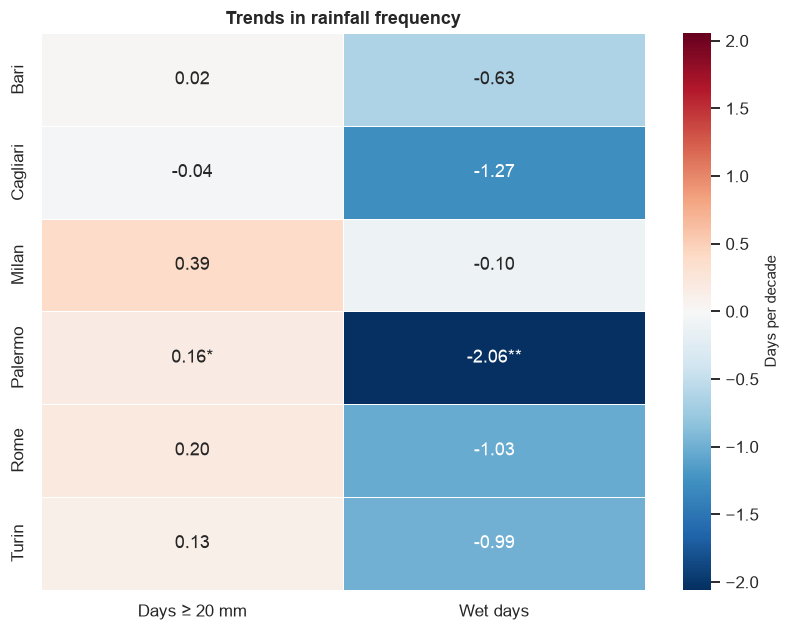

In [56]:
rainfall_frequency = rainfall_trends.loc[
    rainfall_trends["metric"].isin(["wet_days", "heavy_rain_days"])
]
figure = plot_trend_heatmap(
    rainfall_frequency,
    row_column="city",
    column_column="indicator",
    title="Trends in rainfall frequency",
    colorbar_label="Days per decade",
)
figure_path = save_figure(figure, FIGURE_DIR, "15_rainfall_frequency_trends.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
display(figure)
plt.close(figure)

Weather-Report/reports/figures/eda/16_rainfall_intensity_trends.png


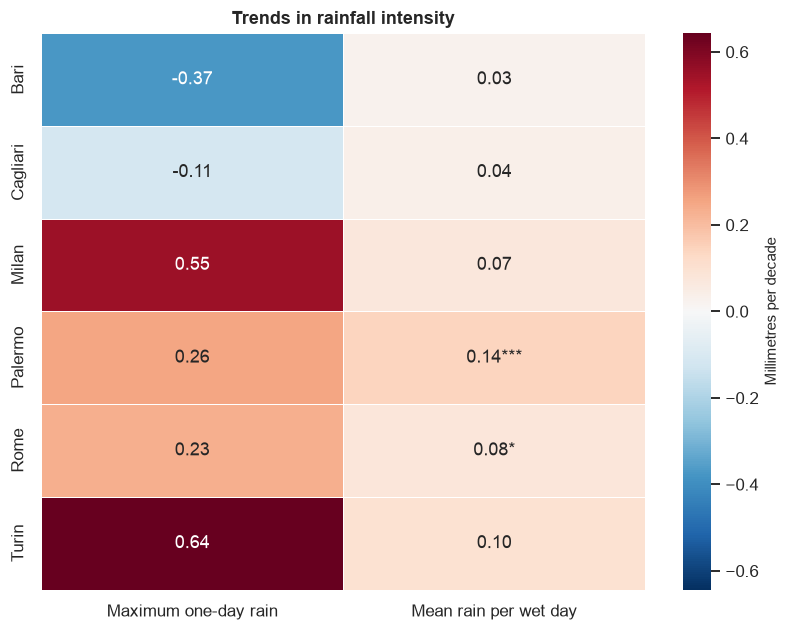

In [57]:
rainfall_intensity = rainfall_trends.loc[
    rainfall_trends["metric"].isin(["rx1day", "wet_day_intensity"])
]
figure = plot_trend_heatmap(
    rainfall_intensity,
    row_column="city",
    column_column="indicator",
    title="Trends in rainfall intensity",
    colorbar_label="Millimetres per decade",
)
figure_path = save_figure(figure, FIGURE_DIR, "16_rainfall_intensity_trends.png")
print(Path(PROJECT_ROOT.name) / figure_path.relative_to(PROJECT_ROOT))
display(figure)
plt.close(figure)

A non-significant annual-total trend does not imply unchanged rainfall behavior. Frequency may decrease while intensity increases, so conclusions must cite the specific indicator being discussed.

## 19. Save statistical result tables

In [58]:
statistical_outputs = {
    "annual_temperature_trends_with_ci.csv": annual_temperature_trends,
    "seasonal_temperature_trends_with_ci.csv": seasonal_temperature_trends,
    "minimum_maximum_temperature_trends.csv": temperature_component_trends,
    "city_interaction_slopes.csv": city_interaction.city_slopes,
    "city_interaction_effects.csv": city_interaction.interaction_effects,
    "extreme_heat_trends.csv": extreme_heat_trends,
    "rainfall_amount_frequency_intensity_trends.csv": rainfall_trends,
}
for filename, dataframe in statistical_outputs.items():
    output_path = DERIVED_DATA_DIR / filename
    dataframe.to_csv(output_path, index=False)
    display_path = Path(PROJECT_ROOT.name) / output_path.relative_to(PROJECT_ROOT)
    print(f"Saved {len(dataframe):,} rows: {display_path}")

Saved 6 rows: Weather-Report/data/processed/annual_temperature_trends_with_ci.csv
Saved 24 rows: Weather-Report/data/processed/seasonal_temperature_trends_with_ci.csv
Saved 18 rows: Weather-Report/data/processed/minimum_maximum_temperature_trends.csv
Saved 6 rows: Weather-Report/data/processed/city_interaction_slopes.csv
Saved 5 rows: Weather-Report/data/processed/city_interaction_effects.csv
Saved 30 rows: Weather-Report/data/processed/extreme_heat_trends.csv
Saved 30 rows: Weather-Report/data/processed/rainfall_amount_frequency_intensity_trends.csv


## 20. Final interpretation

The statistical extension answers the core project questions without relying only on visual impressions. Temperature conclusions should report slopes and confidence intervals. Seasonal and minimum-versus-maximum results explain when and how warming occurs. Interaction terms determine whether cities differ in their rate of change. Extreme-heat trends translate warming into event frequency, while the rainfall section prevents total amount from being confused with frequency or intensity.

These models quantify association with time. They do not by themselves attribute causes, isolate urban heat-island effects or remove the spatial limitations of ERA5 grid-cell data.